<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 9: Principal Component Analysis (PCA) and Performance Evaluation of Classification and Regression Algorithms**



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import LinearSVC, SVC, LinearSVR, SVR
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

##### **1.Implement the PCA on your classification dataset and display the new features with ten instances.**

In [2]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
campus_df = pd.read_csv('campus_preprocessed.csv')

print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed.csv
Dataset loaded successfully!


In [15]:
# Separate independent features and dependent target
X_class = campus_df.drop('placed', axis=1)
y_class = campus_df['placed']

print("Features Shape:", X_class.shape)
print("Target Shape:", y_class.shape)

Features Shape: (100000, 33)
Target Shape: (100000,)


In [17]:
# Split the dataset into 80% training and 20% testing data
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training Features Shape:", X_train_class.shape)
print("Testing Features Shape:", X_test_class.shape)

Training Features Shape: (80000, 33)
Testing Features Shape: (20000, 33)


In [18]:
# Standardize the features
scaler_class = StandardScaler()

X_train_class_scaled = scaler_class.fit_transform(X_train_class)
X_test_class_scaled = scaler_class.transform(X_test_class)

print("Classification features standardized successfully.")

Classification features standardized successfully.


In [19]:
# Apply PCA while retaining 95% of the variance
pca_class = PCA(n_components=0.95)

X_train_class_pca = pca_class.fit_transform(X_train_class_scaled)
X_test_class_pca = pca_class.transform(X_test_class_scaled)

print("Original Number of Features:", X_train_class.shape[1])
print("Number of Principal Components:", pca_class.n_components_)
print("Training Data Shape After PCA:", X_train_class_pca.shape)
print("Testing Data Shape After PCA:", X_test_class_pca.shape)

print("\nTotal Explained Variance:",
      round(sum(pca_class.explained_variance_ratio_), 4))

Original Number of Features: 33
Number of Principal Components: 25
Training Data Shape After PCA: (80000, 25)
Testing Data Shape After PCA: (20000, 25)

Total Explained Variance: 0.9528


In [20]:
# Create principal component column names
class_pc_columns = [
    f'PC{i+1}' for i in range(pca_class.n_components_)
]

# Convert PCA-transformed training data into a DataFrame
classification_pca_df = pd.DataFrame(
    X_train_class_pca,
    columns=class_pc_columns
)

# Add the corresponding target values
classification_pca_df['placed'] = y_train_class.reset_index(drop=True)

print("First 10 Instances of the Classification Dataset After PCA:")
display(classification_pca_df.head(10))

First 10 Instances of the Classification Dataset After PCA:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,placed
0,-0.158588,0.715359,1.309292,-1.283827,-0.311377,-1.414251,0.500294,-0.396315,-1.198224,0.832522,...,-0.703662,-0.784466,-0.447758,-0.210206,0.148019,0.511595,-0.046478,-1.437139,-1.068264,1
1,-1.545260,0.824111,1.248045,-1.207715,1.611115,1.294228,-0.650094,-0.576431,-0.406045,-0.741279,...,-0.542628,0.934365,-0.579952,-1.207204,-0.489089,-0.900100,-1.014234,-0.418150,0.430844,1
2,-2.373955,-0.899176,-1.786993,1.748056,1.114154,-1.058644,-0.025921,1.004110,2.019394,0.448785,...,-0.733535,2.075449,1.185390,0.173562,0.628934,0.641137,0.992128,-0.408642,0.370431,0
3,-0.805128,0.130780,2.892242,-1.221976,1.287315,-0.724082,-0.719659,-0.785279,0.978982,-0.688619,...,-0.021915,-0.138080,-0.640754,0.949664,-0.759786,-0.814937,-0.999637,-0.449618,0.449025,1
4,0.338589,-2.528576,-0.772515,-1.278336,-1.924250,-1.086803,3.053805,-1.284971,-0.962515,1.642096,...,-0.759212,0.009417,0.072144,2.024446,0.335128,0.589711,0.027613,1.362307,0.492214,1
5,1.033557,-2.647285,-0.631898,-1.281658,-1.876879,-1.145905,-0.757052,-0.979662,-1.393302,-1.181498,...,-1.662202,-0.768198,2.294264,1.305709,-0.469972,-0.688866,-1.008406,-0.368753,0.520336,0
6,-0.140417,-1.326845,-1.570785,-1.196728,0.120237,1.389107,-1.364423,0.663366,-0.224850,0.624707,...,0.530348,0.662464,-0.084799,-0.835723,-1.331924,0.529861,0.004547,0.564633,-1.028145,1
7,2.217645,0.808094,0.627566,0.087984,1.132156,-1.408049,1.451840,-2.177279,-1.343387,-0.453115,...,0.849284,1.051202,-0.088589,0.873691,1.108928,-0.875131,1.420890,-0.058714,0.387470,1
8,-2.865326,-3.032087,1.584252,1.695665,-1.735654,-0.188058,1.787055,1.869577,-0.083986,-0.956683,...,-0.969695,-0.456042,-0.900481,1.090421,0.488428,-0.890397,-0.362911,0.967040,0.524103,1
9,0.737588,0.844681,0.827972,0.183264,0.120238,1.379660,-1.367678,0.655856,-0.212323,0.725264,...,0.970673,-0.019773,0.648812,0.579684,-1.150720,0.596191,0.007959,0.541473,-1.045656,1


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.079563,0.079563
1,PC2,0.077498,0.157060
2,PC3,0.076934,0.233994
3,PC4,0.052443,0.286437
4,PC5,0.046558,0.332995
5,PC6,0.045293,0.378287
6,PC7,0.043120,0.421408
7,PC8,0.043045,0.464453
8,PC9,0.037441,0.501894
9,PC10,0.035070,0.536963


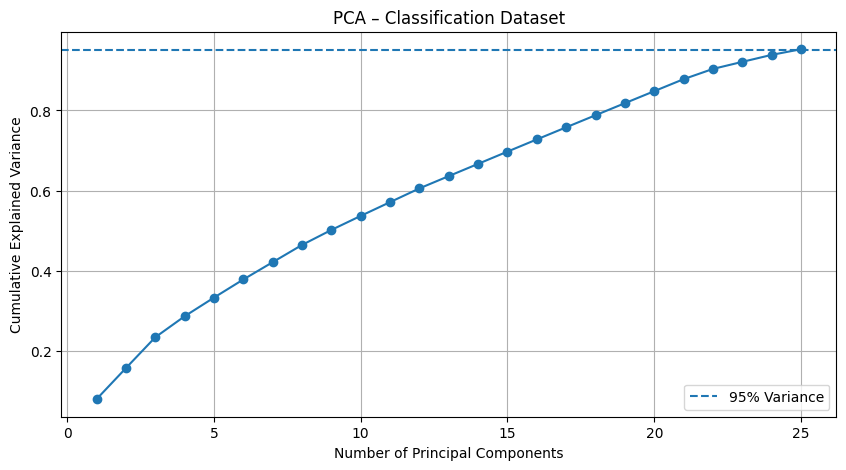

In [21]:
# Display explained variance of each principal component
class_variance_df = pd.DataFrame({
    'Principal Component': class_pc_columns,
    'Explained Variance Ratio': pca_class.explained_variance_ratio_,
    'Cumulative Explained Variance':
        np.cumsum(pca_class.explained_variance_ratio_)
})

display(class_variance_df)

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, pca_class.n_components_ + 1),
    np.cumsum(pca_class.explained_variance_ratio_),
    marker='o'
)

plt.axhline(y=0.95, linestyle='--', label='95% Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA – Classification Dataset')
plt.legend()
plt.grid()
plt.show()

##### **2.Implement the classification ML models such as KNN, Logistic regression, Naïve bay’s, decision tree, random forest, SVM, KSVM, LDA after implementing PCA and find the performances like Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve for classification.**

In [22]:
# Initialize classification models
classification_models = {
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'SVM': LinearSVC(
        max_iter=5000,
        random_state=42
    ),

    'KSVM': SVC(
        kernel='rbf',
        random_state=42
    ),

    'LDA': LinearDiscriminantAnalysis()
}

print("Classification models initialized successfully.")

Classification models initialized successfully.


In [23]:
# Store trained models and their predictions
trained_class_models = {}
class_predictions = {}
class_probabilities = {}

# Train all models except KSVM first
for model_name, model in classification_models.items():

    if model_name == 'KSVM':
        continue

    print("Training:", model_name)

    model.fit(X_train_class_pca, y_train_class)

    trained_class_models[model_name] = model
    class_predictions[model_name] = model.predict(X_test_class_pca)

    # Obtain scores for ROC curve
    if hasattr(model, 'predict_proba'):
        class_probabilities[model_name] = model.predict_proba(
            X_test_class_pca
        )[:, 1]

    else:
        class_probabilities[model_name] = model.decision_function(
            X_test_class_pca
        )

print("\nAll full-training classification models trained.")

Training: KNN
Training: Logistic Regression
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest
Training: SVM
Training: LDA

All full-training classification models trained.


In [24]:
# RBF Kernel SVM can be computationally expensive.
# Therefore, train it using a representative sample of the training data.

ksvm_sample_size = min(5000, len(X_train_class_pca))

X_ksvm_sample, _, y_ksvm_sample, _ = train_test_split(
    X_train_class_pca,
    y_train_class,
    train_size=ksvm_sample_size,
    random_state=42,
    stratify=y_train_class
)

ksvm_model = classification_models['KSVM']

print("Training KSVM using", ksvm_sample_size, "training instances.")

ksvm_model.fit(X_ksvm_sample, y_ksvm_sample)

trained_class_models['KSVM'] = ksvm_model
class_predictions['KSVM'] = ksvm_model.predict(X_test_class_pca)

class_probabilities['KSVM'] = ksvm_model.decision_function(
    X_test_class_pca
)

print("KSVM trained successfully.")

Training KSVM using 5000 training instances.
KSVM trained successfully.


In [25]:
# Calculate performance metrics for all classification models
classification_results = []

for model_name in classification_models.keys():

    y_pred = class_predictions[model_name]
    y_score = class_probabilities[model_name]

    accuracy = accuracy_score(y_test_class, y_pred)
    precision = precision_score(
        y_test_class, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test_class, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test_class, y_pred, zero_division=0
    )
    auc = roc_auc_score(y_test_class, y_score)

    classification_results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc
    })

classification_results_df = pd.DataFrame(classification_results)

print("Classification Model Performance:")
display(
    classification_results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

Classification Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,0.85840,0.875414,0.970390,0.920458,0.841353
1,LDA,0.85760,0.876596,0.967547,0.919829,0.839389
2,SVM,0.85755,0.866980,0.981938,0.920885,0.841325
3,Naive Bayes,0.85650,0.871029,0.974298,0.919774,0.829130
4,KSVM,0.85500,0.861059,0.987623,0.920009,0.782046
5,Random Forest,0.85415,0.864326,0.981286,0.919100,0.818618
6,KNN,0.83990,0.863511,0.962513,0.910328,0.697451
7,Decision Tree,0.78745,0.878815,0.867938,0.873343,0.609467



Confusion Matrix – KNN
[[  545  2569]
 [  633 16253]]


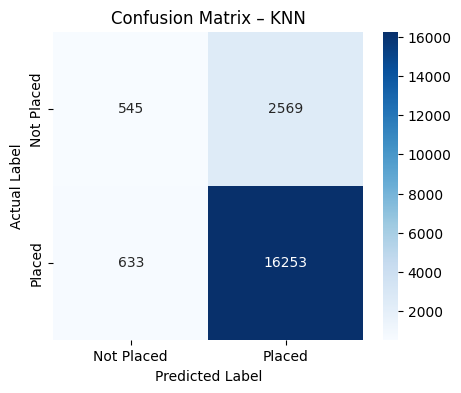


Confusion Matrix – Logistic Regression
[[  782  2332]
 [  500 16386]]


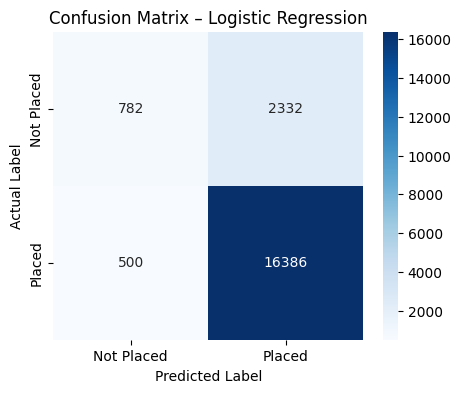


Confusion Matrix – Naive Bayes
[[  678  2436]
 [  434 16452]]


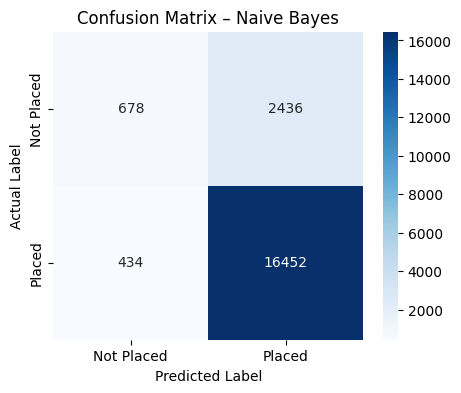


Confusion Matrix – Decision Tree
[[ 1093  2021]
 [ 2230 14656]]


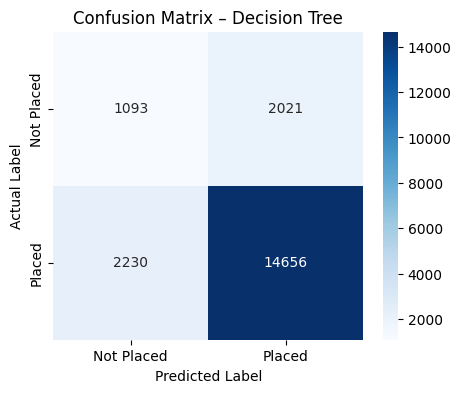


Confusion Matrix – Random Forest
[[  513  2601]
 [  316 16570]]


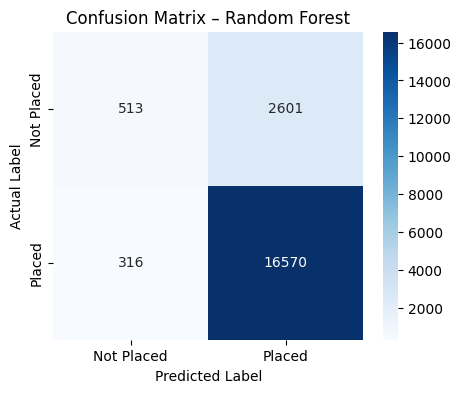


Confusion Matrix – SVM
[[  570  2544]
 [  305 16581]]


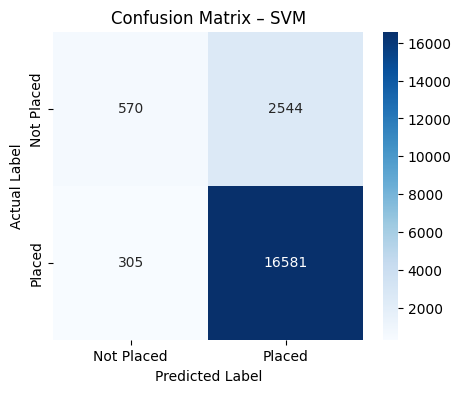


Confusion Matrix – KSVM
[[  423  2691]
 [  209 16677]]


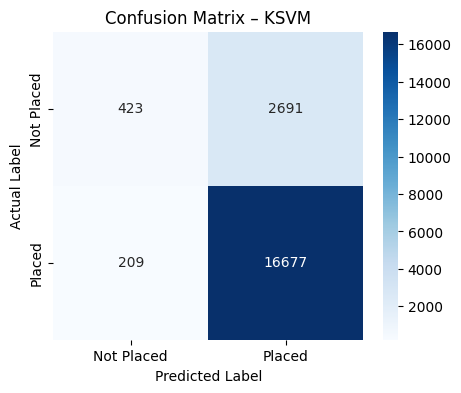


Confusion Matrix – LDA
[[  814  2300]
 [  548 16338]]


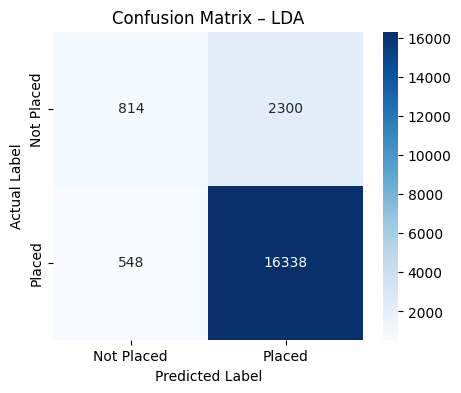

In [26]:
# Display confusion matrices for all classification models
for model_name in classification_models.keys():

    cm = confusion_matrix(
        y_test_class,
        class_predictions[model_name]
    )

    print("\nConfusion Matrix –", model_name)
    print(cm)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Placed', 'Placed'],
        yticklabels=['Not Placed', 'Placed']
    )

    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.title('Confusion Matrix – ' + model_name)
    plt.show()

In [27]:
# Display detailed classification reports
for model_name in classification_models.keys():

    print("\nClassification Report –", model_name)

    print(
        classification_report(
            y_test_class,
            class_predictions[model_name],
            target_names=['Not Placed', 'Placed'],
            zero_division=0
        )
    )


Classification Report – KNN
              precision    recall  f1-score   support

  Not Placed       0.46      0.18      0.25      3114
      Placed       0.86      0.96      0.91     16886

    accuracy                           0.84     20000
   macro avg       0.66      0.57      0.58     20000
weighted avg       0.80      0.84      0.81     20000


Classification Report – Logistic Regression
              precision    recall  f1-score   support

  Not Placed       0.61      0.25      0.36      3114
      Placed       0.88      0.97      0.92     16886

    accuracy                           0.86     20000
   macro avg       0.74      0.61      0.64     20000
weighted avg       0.83      0.86      0.83     20000


Classification Report – Naive Bayes
              precision    recall  f1-score   support

  Not Placed       0.61      0.22      0.32      3114
      Placed       0.87      0.97      0.92     16886

    accuracy                           0.86     20000
   macro avg     

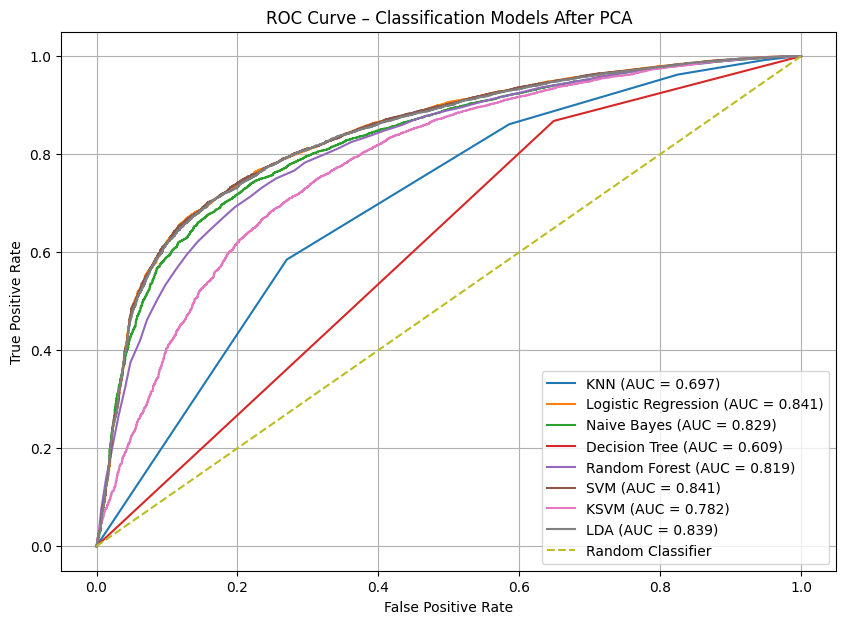

In [28]:
# Plot ROC curves for all classification models
plt.figure(figsize=(10, 7))

for model_name in classification_models.keys():

    y_score = class_probabilities[model_name]

    fpr, tpr, thresholds = roc_curve(
        y_test_class,
        y_score
    )

    auc = roc_auc_score(y_test_class, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Classification Models After PCA')
plt.legend(loc='lower right')
plt.grid()
plt.show()

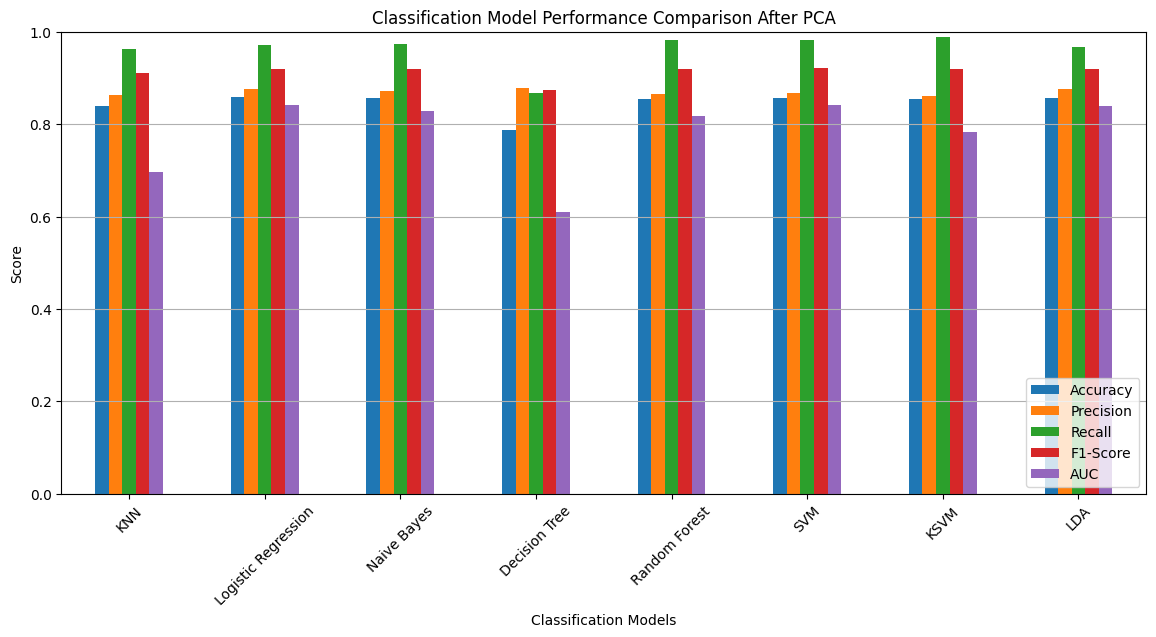

In [29]:
# Compare classification model performances
classification_comparison = classification_results_df.set_index('Model')

classification_comparison.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Classification Model Performance Comparison After PCA')
plt.ylabel('Score')
plt.xlabel('Classification Models')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

##### **3.Implement the PCA on your regression dataset and display the new features with ten instances.**

In [30]:
# Loading the regression dataset

from google.colab import files
uploaded = files.upload()

uber_df = pd.read_csv('uber_preprocessed.csv')
print("Dataset loaded successfully!")

Saving uber_preprocessed.csv to uber_preprocessed.csv
Dataset loaded successfully!


In [32]:
# Separate independent features and dependent target
X_reg = uber_df.drop('fare_amount', axis=1)
y_reg = uber_df['fare_amount']

print("Features Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)

Features Shape: (194918, 10)
Target Shape: (194918,)


In [34]:
# Split the dataset into 80% training and 20% testing data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training Features Shape:", X_train_reg.shape)
print("Testing Features Shape:", X_test_reg.shape)

Training Features Shape: (155934, 10)
Testing Features Shape: (38984, 10)


In [35]:
# Standardize the regression features
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Regression features standardized successfully.")

Regression features standardized successfully.


In [36]:
# Apply PCA while retaining 95% of the variance
pca_reg = PCA(n_components=0.95)

X_train_reg_pca = pca_reg.fit_transform(X_train_reg_scaled)
X_test_reg_pca = pca_reg.transform(X_test_reg_scaled)

print("Original Number of Features:", X_train_reg.shape[1])
print("Number of Principal Components:", pca_reg.n_components_)
print("Training Data Shape After PCA:", X_train_reg_pca.shape)
print("Testing Data Shape After PCA:", X_test_reg_pca.shape)

print("\nTotal Explained Variance:",
      round(sum(pca_reg.explained_variance_ratio_), 4))

Original Number of Features: 10
Number of Principal Components: 10
Training Data Shape After PCA: (155934, 10)
Testing Data Shape After PCA: (38984, 10)

Total Explained Variance: 1.0


In [37]:
# Create principal component column names
reg_pc_columns = [
    f'PC{i+1}' for i in range(pca_reg.n_components_)
]

# Convert PCA-transformed training data into a DataFrame
regression_pca_df = pd.DataFrame(
    X_train_reg_pca,
    columns=reg_pc_columns
)

# Add the corresponding target values
regression_pca_df['fare_amount'] = y_train_reg.reset_index(drop=True)

print("First 10 Instances of the Regression Dataset After PCA:")
display(regression_pca_df.head(10))

First 10 Instances of the Regression Dataset After PCA:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,fare_amount
0,0.923429,0.046575,0.612601,0.144294,-0.081227,0.360163,0.572953,1.048759,-0.359440,-0.305350,7.5
1,-0.104158,-0.454506,0.329715,-1.534151,-0.279629,-1.228425,-0.694621,0.116661,-0.104860,-0.391378,8.1
2,0.025131,-0.901312,1.041044,-1.458689,-0.446492,-0.465870,0.134092,0.447940,0.385865,0.620649,6.9
3,-1.418233,0.498598,-0.869186,1.029255,-1.437980,-0.691562,-0.379051,-0.204478,-0.191273,-0.029556,4.5
4,-0.208293,-0.634494,-2.281531,0.387651,1.730081,-2.323064,-2.360198,-0.596876,-0.386653,0.071440,6.5
5,0.957398,1.437390,0.534744,1.568127,-0.700216,0.164660,-0.167228,1.424359,-0.105668,0.084962,22.0
6,-0.185684,0.124713,0.160838,0.271051,-1.114976,-1.038232,-0.354795,1.609912,1.008905,1.022172,23.0
7,-0.909622,-0.106622,0.909575,-0.019821,-0.920641,-0.719852,-0.078603,0.942712,-0.001582,-0.009163,4.5
8,1.159418,-1.024157,0.046493,-0.909548,-1.357486,-1.036365,-0.728167,-0.845629,-0.228790,-0.051122,3.7
9,1.437533,-0.603258,1.589169,-0.855191,-0.447275,-0.502738,0.475259,0.304910,-0.379739,-0.252522,6.1


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.149329,0.149329
1,PC2,0.127946,0.277274
2,PC3,0.111439,0.388713
3,PC4,0.108860,0.497573
4,PC5,0.101270,0.598843
5,PC6,0.100166,0.699009
6,PC7,0.090045,0.789053
7,PC8,0.087929,0.876982
8,PC9,0.066722,0.943705
9,PC10,0.056295,1.000000


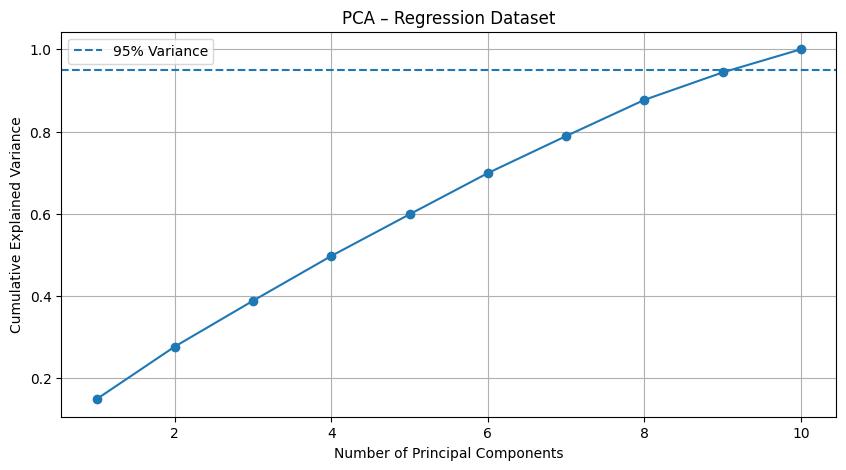

In [38]:
# Display explained variance of each principal component
reg_variance_df = pd.DataFrame({
    'Principal Component': reg_pc_columns,
    'Explained Variance Ratio': pca_reg.explained_variance_ratio_,
    'Cumulative Explained Variance':
        np.cumsum(pca_reg.explained_variance_ratio_)
})

display(reg_variance_df)

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, pca_reg.n_components_ + 1),
    np.cumsum(pca_reg.explained_variance_ratio_),
    marker='o'
)

plt.axhline(y=0.95, linestyle='--', label='95% Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA – Regression Dataset')
plt.legend()
plt.grid()
plt.show()

##### **4.Implement regression ML models. (KNN, multiple linear regression, SVM, KSVM, decision tree, random forest) after implementing PCA on the regression dataset and calculate the performances such as MAE, MSE, RMSE, and R2 for regression.**

In [39]:
# Initialize regression models
regression_models = {
    'KNN': KNeighborsRegressor(
        n_neighbors=5,
        n_jobs=-1
    ),

    'Multiple Linear Regression': LinearRegression(),

    'SVM': LinearSVR(
        max_iter=5000,
        random_state=42
    ),

    'KSVM': SVR(
        kernel='rbf'
    ),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Regression models initialized successfully.")

Regression models initialized successfully.


In [40]:
# Store trained models and their predictions
trained_reg_models = {}
reg_predictions = {}

# Train all models except KSVM first
for model_name, model in regression_models.items():

    if model_name == 'KSVM':
        continue

    print("Training:", model_name)

    model.fit(X_train_reg_pca, y_train_reg)

    trained_reg_models[model_name] = model
    reg_predictions[model_name] = model.predict(X_test_reg_pca)

print("\nAll full-training regression models trained.")

Training: KNN
Training: Multiple Linear Regression
Training: SVM
Training: Decision Tree
Training: Random Forest

All full-training regression models trained.


In [41]:
# RBF Kernel SVR can be computationally expensive.
# Therefore, train it using a sample of the training data.

ksvm_reg_sample_size = min(5000, len(X_train_reg_pca))

X_ksvm_reg_sample, _, y_ksvm_reg_sample, _ = train_test_split(
    X_train_reg_pca,
    y_train_reg,
    train_size=ksvm_reg_sample_size,
    random_state=42
)

ksvm_reg_model = regression_models['KSVM']

print("Training KSVM using", ksvm_reg_sample_size, "training instances.")

ksvm_reg_model.fit(X_ksvm_reg_sample, y_ksvm_reg_sample)

trained_reg_models['KSVM'] = ksvm_reg_model
reg_predictions['KSVM'] = ksvm_reg_model.predict(X_test_reg_pca)

print("KSVM trained successfully.")

Training KSVM using 5000 training instances.
KSVM trained successfully.


In [42]:
# Calculate performance metrics for all regression models
regression_results = []

for model_name in regression_models.keys():

    y_pred = reg_predictions[model_name]

    mae = mean_absolute_error(y_test_reg, y_pred)
    mse = mean_squared_error(y_test_reg, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_reg, y_pred)

    regression_results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

regression_results_df = pd.DataFrame(regression_results)

print("Regression Model Performance:")
display(
    regression_results_df.sort_values(
        by='R2 Score',
        ascending=False
    ).reset_index(drop=True)
)

Regression Model Performance:


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,1.925089,14.972644,3.869450,0.838255
1,KNN,2.574742,20.742301,4.554372,0.775927
2,Decision Tree,2.787665,30.869695,5.556050,0.666524
3,KSVM,2.948375,31.071156,5.574151,0.664348
4,Multiple Linear Regression,5.070731,65.111303,8.069158,0.296623
5,SVM,4.848494,68.210945,8.258992,0.263138


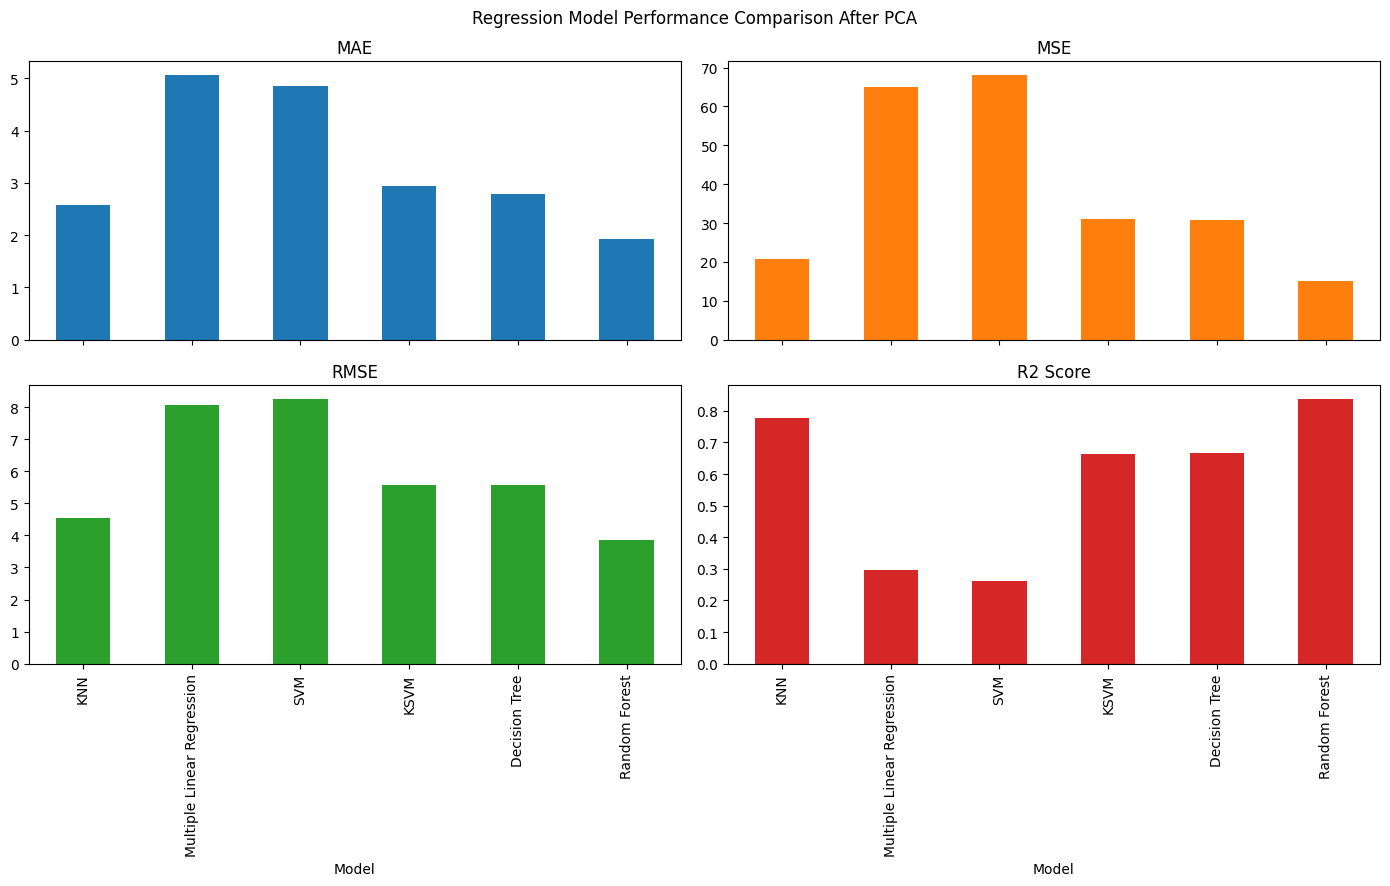

In [43]:
# Compare regression model performances
regression_comparison = regression_results_df.set_index('Model')

regression_comparison.plot(
    kind='bar',
    subplots=True,
    layout=(2, 2),
    figsize=(14, 9),
    legend=False
)

plt.suptitle('Regression Model Performance Comparison After PCA')
plt.tight_layout()
plt.show()

In [44]:
# Compare actual and predicted values for each regression model
for model_name in regression_models.keys():

    comparison_df = pd.DataFrame({
        'Actual Fare': y_test_reg.iloc[:10].values,
        'Predicted Fare': reg_predictions[model_name][:10]
    })

    print("\nActual vs Predicted Values –", model_name)
    display(comparison_df)


Actual vs Predicted Values – KNN


,Actual Fare,Predicted Fare
0,4.1,4.960
1,14.1,12.740
2,3.5,7.000
3,11.5,6.600
4,8.0,8.800
5,26.5,29.014
6,15.0,10.000
7,15.0,14.500
8,31.7,11.740
9,8.9,10.660



Actual vs Predicted Values – Multiple Linear Regression


,Actual Fare,Predicted Fare
0,4.1,8.310388
1,14.1,16.719929
2,3.5,9.705098
3,11.5,9.688399
4,8.0,12.133388
5,26.5,16.166725
6,15.0,10.659265
7,15.0,14.490858
8,31.7,10.400399
9,8.9,9.405073



Actual vs Predicted Values – SVM


,Actual Fare,Predicted Fare
0,4.1,6.546888
1,14.1,16.860735
2,3.5,7.565828
3,11.5,7.556672
4,8.0,10.356781
5,26.5,16.909566
6,15.0,8.208080
7,15.0,12.094605
8,31.7,10.710614
9,8.9,8.702536


... (2 outputs left out)


Actual vs Predicted Values – Decision Tree


,Actual Fare,Predicted Fare
0,4.1,4.9
1,14.1,17.7
2,3.5,3.5
3,11.5,6.0
4,8.0,8.5
5,26.5,25.3
6,15.0,13.3
7,15.0,18.0
8,31.7,14.9
9,8.9,12.1



Actual vs Predicted Values – Random Forest


,Actual Fare,Predicted Fare
0,4.1,5.4910
1,14.1,16.2007
2,3.5,4.3890
3,11.5,6.1350
4,8.0,7.2950
5,26.5,24.8623
6,15.0,15.3150
7,15.0,17.2130
8,31.7,14.1140
9,8.9,11.6990


# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1